# 06 — Evaluation, Results & Conclusion

**Lab 2 — Group 4 | CIFAR-10**

Bước 7: đọc kết quả từ notebook 04 hoặc outputs gốc, so sánh, chọn model và đánh giá test.

Cấu hình được đặt trực tiếp trong cell code đầu tiên của notebook. `review` đọc kết quả lịch sử; `full` chạy mới. Mỗi notebook có thể mở bằng kernel riêng.

In [1]:
from pathlib import Path
import sys, os
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs').is_dir() and (p/'src').is_dir()), None)
assert ROOT is not None, 'Hãy mở notebook trong thư mục dự án đã giải nén.'
sys.path.insert(0, str(ROOT))
# Cấu hình trực tiếp trong notebook (không cần file cấu hình riêng).
MODE = "review"  # review: kết quả gốc; full: chạy thực tế
RUN_ID = "run_01"  # notebook 04–06 phải dùng cùng tên khi chạy full
DEVICE_OVERRIDE = "auto"  # auto / cpu / cuda
CPU_THREADS = 1
LIVE = MODE == "full"
assert MODE in ("review", "full")
DOWNLOAD = True
import io, json, random, hashlib, time, gc
from pathlib import Path
from datetime import datetime
from uuid import uuid4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

DATA_DIR = ROOT / 'data'
SESSION_DIR = ROOT / 'outputs' / 'notebook_runs' / RUN_ID
FIG_DIR = SESSION_DIR / 'figures'
SAVE_FIGS = LIVE

def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

random.seed(SEED)
np.random.seed(SEED)
if LIVE:
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import DataLoader, Subset, random_split
    from torchvision import transforms, models
    from PIL import Image
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    from torch.utils.tensorboard import SummaryWriter
    import torch.nn.functional as F

    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

    set_seed(SEED)
    DEVICE = torch.device(("cuda" if torch.cuda.is_available() else "cpu")
                          if DEVICE_OVERRIDE == "auto" else DEVICE_OVERRIDE)
    if DEVICE.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA không khả dụng. Chọn CPU hoặc sửa môi trường.")
    if DEVICE.type == "cpu":
        torch.set_num_threads(CPU_THREADS)
    print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
    print("Device:", DEVICE)
    print("Data:", DATA_DIR, "| Output mới:", SESSION_DIR)
else:
    print("Review: không cần import PyTorch, không tạo file training.")

Review: không cần import PyTorch, không tạo file training.


## 7.1. Đọc bảng và lịch sử thực nghiệm
Không lấy test accuracy làm tiêu chí chọn model.

In [2]:
run_root=SESSION_DIR/'training' if LIVE else ROOT/'outputs'
summary_path=run_root/'experiment_summary.csv'
assert summary_path.is_file(), 'Chạy notebook 04 với cùng MODE và RUN_ID trước.'
summary=pd.read_csv(summary_path).dropna(subset=['best_val_accuracy','best_val_loss']).copy()
assert len(summary)==5, 'Cần đủ 5 thực nghiệm đã hoàn thành.'
histories={}
for name in summary.experiment_name:
    folder=run_root/name if LIVE else run_root/'runs'/name
    histories[name]=pd.read_csv(folder/'history.csv').to_dict('records')
display(summary)
print('Nguồn:', 'thực nghiệm mới' if LIVE else 'kết quả gốc')

,experiment_name,model_name,strategy,learning_rate,batch_size,epochs,seed,best_val_loss,best_val_accuracy,test_accuracy,training_time_sec
0,E1_vgg16,vgg16,classifier_only,0.0010,32,1,42,0.524489,0.8288,NaN,21929.006920
1,E2_densenet121,densenet121,classifier_only,0.0010,32,1,42,0.346216,0.8784,NaN,5407.230531
2,E3_learning_rate,densenet121,classifier_only,0.0001,32,1,42,0.577797,0.8344,NaN,5329.618331
3,E4_batch_size,densenet121,classifier_only,0.0010,64,1,42,0.367412,0.8716,NaN,5499.967411
4,E5_cpu_1epoch,densenet121,finetune_last_layers,0.0001,32,1,42,0.232135,0.9210,0.9181,6135.234429


Nguồn: kết quả gốc


## 7.2. So sánh validation accuracy và loss giữa các thí nghiệm
Learning curves và dấu hiệu tổng quát hóa đã được trình bày ở notebook 05.

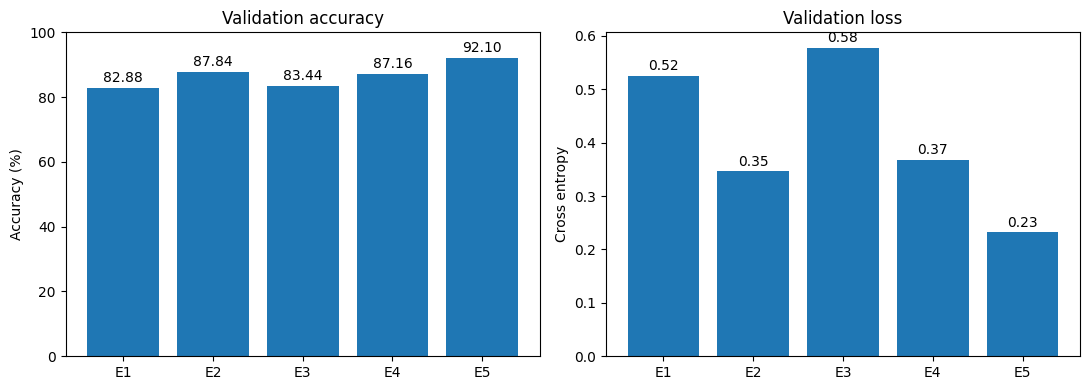

In [3]:
labels = [name.split("_")[0] for name in summary["experiment_name"]]
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].bar(labels, summary["best_val_accuracy"]*100)
axes[0].set(title="Validation accuracy",ylabel="Accuracy (%)",ylim=(0,100))
axes[1].bar(labels, summary["best_val_loss"])
axes[1].set(title="Validation loss",ylabel="Cross entropy")
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f", padding=2)
plt.tight_layout(); plt.show()

## 7.3. Evaluate the Model — Đánh giá mô hình
### 7.1. Chọn mô hình tốt nhất trên validation
Xếp hạng bằng validation accuracy, nếu bằng nhau ưu tiên validation loss thấp hơn. Chỉ đánh giá test sau khi đã chọn xong mô hình.

In [4]:
best = summary.sort_values(["best_val_accuracy","best_val_loss"],ascending=[False,True]).iloc[0]
print("Best model:", best["experiment_name"])
print(f"Validation accuracy: {best['best_val_accuracy']:.2%}")
print(f"Validation loss: {best['best_val_loss']:.6f}")

Best model: E5_cpu_1epoch
Validation accuracy: 92.10%
Validation loss: 0.232135


## 7.4. Test checkpoint đã chọn
Dùng lại config của run đã được chọn, tải state dict từ checkpoint rồi đánh giá trên 10.000 mẫu test bằng `src/evaluate.py`.

In [5]:
if LIVE:
    from src.models import build_model
    from src.data import build_dataloaders
    from src.evaluate import evaluate_model
    cfg=json.loads((run_root/best.experiment_name/'config.json').read_text(encoding='utf-8'))
    cfg.update(pretrained=False, device=str(DEVICE), data_dir=str(DATA_DIR))
    ckpt=torch.load(ROOT/best.checkpoint_path,map_location='cpu',weights_only=True)
    model=build_model(cfg)
    model.load_state_dict(ckpt['model_state_dict'])
    loaders=build_dataloaders(cfg)
    assert len(loaders['test'].dataset)==10000
    test_metrics=evaluate_model(model,loaders['test'],cfg)
    test_metrics['test_samples']=len(loaders['test'].dataset)
    (run_root/'final_test.json').write_text(json.dumps({'selected_run':best.experiment_name,**test_metrics},indent=2),encoding='utf-8')
else:
    metrics=json.loads((run_root/'runs'/best.experiment_name/'metrics.json').read_text(encoding='utf-8'))
    test_metrics=metrics['final_test']
    print('Kết quả test thực đo trước đây, không chạy test mới.')
display(pd.DataFrame({'Metric':list(test_metrics),'Value':list(test_metrics.values())}))
print(f"Test accuracy: {test_metrics['accuracy']:.2%}")

Kết quả test thực đo trước đây, không chạy test mới.


,Metric,Value
0,test_samples,10000
1,checkpoint_path,outputs/checkpoints/E5_cpu_1epoch/best_model.pth
2,test_loss,0.245938
3,accuracy,0.9181
4,precision,0.918185
5,recall,0.9181
6,f1_score,0.917776
7,average,weighted
8,source,Final test terminal output; rounded to 6 decim...


Test accuracy: 91.81%


## 7.5. Nhận xét và kết luận
**Theo kết quả gốc:** E2 (DenseNet121) đạt 87,84%, cao hơn E1 (VGG16) 82,88%. Khi giảm learning rate từ 0,001 xuống 0,0001 trong classifier-only, validation accuracy giảm từ 87,84% xuống 83,44%. Batch size 64 cho 87,16%, thấp hơn batch 32 trong phạm vi thí nghiệm. Fine-tuning E5 đạt 92,10% validation và 91,81% test; weighted F1 91,7776%. Số tham số trainable khác nhau giữa hai kiến trúc, nên không kết luận mô hình nào tốt hơn trong mọi bài toán.

**Kết quả của chế độ đang chạy:** xem bảng ngay phía trên; nếu chạy full thì kết quả có thể thay đổi theo thiết bị/phần mềm.

**Giới hạn:** 5 cấu hình chỉ chạy 1 epoch, 1 seed; chưa đủ phân tích hội tụ/overfitting. E5 10 epoch chưa có kết quả. ZIP không có dataset, checkpoint hoặc TensorBoard event files gốc; chế độ full cần kết nối tải dữ liệu, pretrained weights và tài nguyên tính toán.

**Đối chiếu đề:** hoàn thành luồng thiết lập → tải model → khảo sát → tùy chỉnh → dữ liệu → huấn luyện/TensorBoard/thí nghiệm → đánh giá. Nguồn nhóm: `configs/`, `src/models.py`, `src/data.py`, `src/train.py`, `src/evaluate.py`, `outputs/experiment_summary.csv`, `outputs/runs/`, `reports/sections/02_model.md`, `04_evaluation.md`, `05_experiments.md`.